# Volume Kedua Lambung Perahu Katamaran

**Soal:** hitung volume kedua lambung kapal dari gambar (tampak atas dan tampak samping).

**Asumsi**
- 1 kotak grid = 45 cm × 45 cm (tiap sisi kotak hijau: 5 dash + 4 jeda, masing-masing 5 cm, jadi 5×5 + 4×5 = 45 cm)
- Lantai kapal datar (tanpa keel), jadi tampak depan berupa persegi panjang
- Volume *reserve buoyancy* (ujung kiri dan ujung kanan lambung) **tidak dihitung**
- Dua lambung identik, jadi hitung satu lambung lalu kalikan 2

**Daerah yang dihitung:** dari garis lengkung di kiri sampai garis tegak di kanan, sepanjang ±16 kotak (16 × 45 = 720 cm).

**Metode:** luas penampang di tiap posisi = lebar × kedalaman. Volume = integral luas penampang sepanjang lambung, dihitung dengan aturan trapesium dan Simpson 1/3.

## 1. Data hasil pengukuran dari gambar

Posisi `x` diukur dari garis lengkung kiri (x = 0) sampai garis tegak kanan (x = 16), tiap 1 kotak.
- **Lebar**: dari tampak atas
- **Kedalaman**: dari tampak samping (garis dek sampai dasar lambung)

> Angka ini hasil pembacaan visual (perkiraan). Ganti dengan hasil pengukuranmu sendiri dari grid kalau berbeda.

In [1]:
import numpy as np
import pandas as pd

KOTAK_CM = 45  # 1 kotak = 45 cm (5 dash + 4 jeda, tiap dash/jeda = 5 cm)

# posisi (kotak), dihitung dari garis lengkung kiri
x_kotak = np.arange(0, 17)

# lebar lambung (kotak), dari tampak atas
lebar_kotak = np.array([1.70, 1.90, 2.00, 2.04, 2.04, 2.04, 2.04, 2.04, 2.04,
                        2.04, 2.04, 2.04, 2.04, 1.75, 1.45, 1.20, 0.95])

# kedalaman lambung (kotak), dari tampak samping (dasar naik melengkung di dekat kiri)
dalam_kotak = np.array([1.70, 2.15, 2.50, 2.57, 2.57, 2.57, 2.57, 2.57, 2.57,
                        2.57, 2.57, 2.57, 2.57, 2.57, 2.57, 2.57, 2.57])

df = pd.DataFrame({
    "x (kotak)": x_kotak,
    "lebar (kotak)": lebar_kotak,
    "dalam (kotak)": dalam_kotak,
})
df["x (cm)"] = df["x (kotak)"] * KOTAK_CM
df["lebar (cm)"] = df["lebar (kotak)"] * KOTAK_CM
df["dalam (cm)"] = df["dalam (kotak)"] * KOTAK_CM
df["luas penampang (cm²)"] = df["lebar (cm)"] * df["dalam (cm)"]
df

,x (kotak),lebar (kotak),dalam (kotak),x (cm),lebar (cm),dalam (cm),luas penampang (cm²)
0,0,1.70,1.70,0,76.50,76.50,5852.2500
1,1,1.90,2.15,45,85.50,96.75,8272.1250
2,2,2.00,2.50,90,90.00,112.50,10125.0000
3,3,2.04,2.57,135,91.80,115.65,10616.6700
4,4,2.04,2.57,180,91.80,115.65,10616.6700
5,5,2.04,2.57,225,91.80,115.65,10616.6700
6,6,2.04,2.57,270,91.80,115.65,10616.6700
7,7,2.04,2.57,315,91.80,115.65,10616.6700
8,8,2.04,2.57,360,91.80,115.65,10616.6700
9,9,2.04,2.57,405,91.80,115.65,10616.6700


## 2. Integrasi numerik

In [2]:
x = df["x (cm)"].values
A = df["luas penampang (cm²)"].values

# Aturan trapesium
V_trap = np.trapz(A, x) if hasattr(np, "trapz") else np.trapezoid(A, x)

# Aturan Simpson 1/3 (butuh jumlah interval genap: 16 interval -> OK)
h = x[1] - x[0]
V_simp = h/3 * (A[0] + A[-1] + 4*A[1:-1:2].sum() + 2*A[2:-1:2].sum())

print(f"Volume 1 lambung (trapesium)  : {V_trap:,.0f} cm³ = {V_trap/1000:.2f} liter = {V_trap/1e6:.3f} m³")
print(f"Volume 1 lambung (Simpson 1/3): {V_simp:,.0f} cm³ = {V_simp/1000:.2f} liter = {V_simp/1e6:.3f} m³")

Volume 1 lambung (trapesium)  : 6,878,730 cm³ = 6878.73 liter = 6.879 m³
Volume 1 lambung (Simpson 1/3): 6,887,060 cm³ = 6887.06 liter = 6.887 m³


## 3. Volume kedua lambung

In [3]:
V_total = 2 * V_simp
print(f"Volume kedua lambung = {V_total:,.0f} cm³")
print(f"                     = {V_total/1000:.2f} liter")
print(f"                     = {V_total/1e6:.4f} m³")

Volume kedua lambung = 13,774,121 cm³
                     = 13774.12 liter
                     = 13.7741 m³


## 4. Cek sederhana dan visualisasi

Luas tampak atas bagian yang dihitung: 60,801 cm²
Cek kasar (luas x kedalaman tengah)    : 7,031,592 cm³


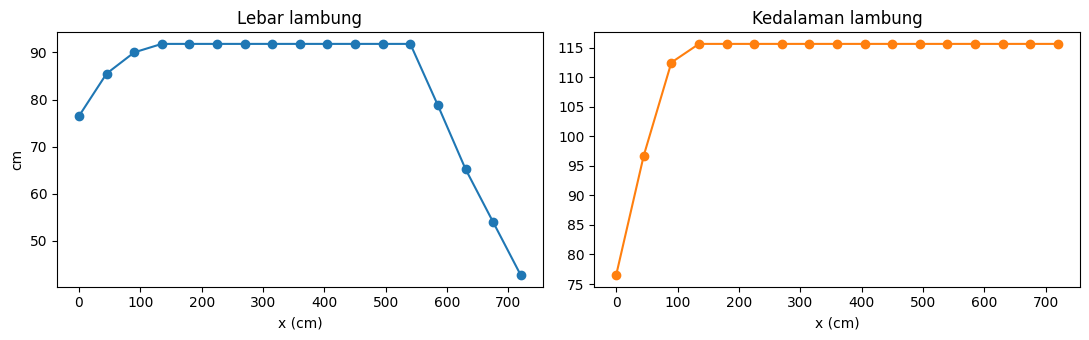

In [4]:
import matplotlib.pyplot as plt

# cek kasar: luas tampak atas x kedalaman rata-rata
luas_atas = np.trapezoid(df["lebar (cm)"], x) if hasattr(np, "trapezoid") else np.trapz(df["lebar (cm)"], x)
print(f"Luas tampak atas bagian yang dihitung: {luas_atas:,.0f} cm²")
print(f"Cek kasar (luas x kedalaman tengah)    : {luas_atas*2.57*KOTAK_CM:,.0f} cm³")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(x, df["lebar (cm)"], marker="o"); ax[0].set_title("Lebar lambung"); ax[0].set_xlabel("x (cm)"); ax[0].set_ylabel("cm")
ax[1].plot(x, df["dalam (cm)"], marker="o", color="tab:orange"); ax[1].set_title("Kedalaman lambung"); ax[1].set_xlabel("x (cm)")
plt.tight_layout(); plt.show()

## 5. Kesimpulan

Volume satu lambung (bagian utama, tanpa reserve buoyancy) dan volume kedua lambung ada pada output di atas.
Hasil ini perkiraan karena lebar dan kedalaman dibaca dari gambar, dengan kemungkinan selisih beberapa persen.